# Analyse du domaine santé

Les fichiers de santé ont été nettoyés dans `03_health_nettoyage.ipynb`. Ici, on part à la découverte des données médicales : on regarde ce qu'elles contiennent, on suit les pistes qui nous paraissent étranges, et on note à chaque fois ce que ça donne, que la piste mène quelque part ou non.

À la fin, on fait le bilan de ce qui est pertinent pour la suite de l'enquête.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest

DOSSIER = Path("data_clean/health")
observations = pd.read_csv(DOSSIER / "clinical_observations.csv", parse_dates=["observation_time"])
patients = pd.read_csv(DOSSIER / "patient_administration.csv", parse_dates=["date_of_birth"])
procedures = pd.read_csv(DOSSIER / "clinical_procedures.csv")
enregistrements = pd.read_csv(DOSSIER / "cardiac_recordings.csv")
signaux = pd.read_csv(DOSSIER / "cardiac_signal_samples.csv")

# Le nom et la profession de chaque patient, pour pouvoir lire les résultats
patients["nom"] = patients["given_name"] + " " + patients["family_name"]
infos = patients.set_index("patient_number")[["nom", "occupation_text"]]

## 1. Qu'est-ce qu'on mesure chez les patients ?

Le fichier `clinical_observations` contient les mesures faites pendant les consultations. Avant toute analyse, on veut savoir **quelles mesures** existent. Les codes (`RPULSE`, `THORVIB`…) ne sont pas parlants, mais la colonne `observation_name` donne leur nom complet. On affiche aussi l'unité et la plage de valeurs attendue.

In [2]:
liste_mesures = observations.groupby("observation_code").agg(
    nom_complet=("observation_name", "first"),
    unite=("unit", "first"),
    plage_attendue=("reference_range_text", "first"),
    nombre_de_mesures=("observation_number", "count"),
)
liste_mesures

,nom_complet,unite,plage_attendue,nombre_de_mesures
observation_code,,,,
AGECOND,age-related condition count,count,0–10,240
APICAL,apical cardiac rate,bpm,50–110,1017
BALANCE,balance score,index,0–100,947
BINOCOORD,binocular coordination,NaN,normal; reduced; atypical; not tested,240
BIOAGE,estimated biological age,years,18–100,934
CAMMATCH,camera match confidence,index,0–100,240
CARDOUT,estimated cardiac output,l/min,3.5–8.0,941
COGNITIVE,cognitive score,index,0–100,948
CVRISK,cardiovascular risk score,index,0–100,240


On peut ranger ces 32 mesures en deux familles.

D'abord, des mesures qu'on retrouve dans n'importe quel bilan de santé : le pouls (`RPULSE`, `PPULSE`), la tension (`SYSBP`, `DIABP`), l'oxygène dans le sang (`O2SAT`), la vue (`VALEFT`, `VARIGHT`), la vitesse de marche (`WALKSPD`)…

Ensuite, des mesures qui paraissent étranges pour un examen médical :
- `BIOAGE` : un « âge biologique estimé » ;
- `IDCONS` et `CAMMATCH` : un score de cohérence d'identité et la confiance d'une caméra à reconnaître la personne ;
- `THERMQUAL` : la qualité de détection d'une caméra thermique ;
- `THORVIB` et `THORPEAK` : des vibrations et un « pic secondaire » dans la poitrine ;
- `LATSWAY` : l'oscillation de la personne de gauche à droite quand elle marche ;
- `LEFTEYE` et `RIGHTEYE` : la déviation de chaque œil, mesurée séparément.

Pourquoi mesurer la reconnaissance d'une personne par une caméra pendant un bilan de santé ? On note ces mesures comme **pistes** à suivre.

## 2. Mettre chaque patient sur une seule ligne

Pour l'instant, chaque ligne du fichier contient une seule mesure, faite à un moment donné. Un même patient apparaît donc sur des dizaines de lignes : une pour son pouls, une pour sa tension, puis à nouveau son pouls à la consultation suivante…

Pour comparer les patients entre eux, on veut un tableau avec **une ligne par patient** et **une colonne par mesure**. Quand un patient a été mesuré plusieurs fois, on garde la moyenne.

In [3]:
tableau = observations.pivot_table(index="patient_number",
                                   columns="observation_code",
                                   values="numeric_value",
                                   aggfunc="mean")
print(tableau.shape)
tableau.head()

(240, 27)


observation_code,AGECOND,APICAL,BALANCE,BIOAGE,CAMMATCH,CARDOUT,COGNITIVE,CVRISK,DIABP,GAITSYM,...,RIGHTEYE,RPULSE,STROKEVOL,SYSBP,THERMQUAL,THORPEAK,THORVIB,VALEFT,VARIGHT,WALKSPD
patient_number,,,,,,,,,,,,,,,,,,,,,
PAT-31001,0.0,89.100000,92.750000,20.625000,87.5,5.615000,84.475000,43.9,55.0,87.0,...,16.0,66.325000,78.6,131.4,98.0,24.225000,31.30,0.91,0.78,1.11
PAT-31002,2.0,91.500000,74.475000,49.720000,78.6,5.940000,88.900000,36.9,75.5,75.4,...,6.2,73.920000,49.5,110.4,88.5,32.750000,31.02,0.78,0.97,1.17
PAT-31003,0.0,85.560000,79.700000,58.940000,93.7,6.198000,88.566667,68.0,69.4,87.6,...,-3.4,77.740000,78.7,140.2,81.4,49.020000,17.88,0.94,0.97,1.14
PAT-31004,1.0,76.633333,78.433333,75.833333,86.6,3.690000,98.766667,45.4,73.8,97.0,...,5.0,56.533333,63.2,121.6,90.3,19.166667,42.50,0.95,0.89,1.40
PAT-31005,1.0,60.850000,79.100000,48.275000,92.8,4.356667,87.333333,38.3,72.6,96.9,...,-1.8,66.475000,83.8,115.3,86.3,34.766667,34.70,0.91,0.98,1.12


On obtient 240 patients et 27 colonnes. Il manque 5 mesures, celles dont le résultat est un mot et non un nombre : on les regarde maintenant.

## 3. Les mesures qui donnent un mot

Cinq mesures ont pour résultat un mot (colonne `text_value`) : `OCULAR` (le suivi des yeux), `BINOCOORD` (la coordination des deux yeux), `VESTIB` (l'équilibre de l'oreille interne), `MUSC` (les muscles et les os) et `NEURO` (le système nerveux). Ce sont des catégories, comme « normal » ou « atypical ».

In [4]:
textuelles = observations[observations["text_value"].notna()]
pd.crosstab(textuelles["observation_code"], textuelles["text_value"])

text_value,abnormal,atypical,inconclusive,mild,none,normal,reduced
observation_code,,,,,,,
BINOCOORD,0,14,0,0,0,148,78
MUSC,0,0,0,87,153,0,0
NEURO,0,0,0,70,170,0,0
OCULAR,0,42,455,0,0,413,0
VESTIB,11,0,60,0,0,169,0


Les résultats « atypical » et « abnormal » sont rares : 67 sur 1 871, soit environ 4 %. Ce qui est rare nous intéresse, parce qu'on cherche ce qui sort de l'ordinaire.

On pourrait transformer chaque catégorie en colonne de 0 et de 1, mais ça ajouterait beaucoup de colonnes pour une information simple. On choisit plutôt de calculer, pour chaque patient, **la part de ses résultats qui sont « atypical » ou « abnormal »**. On ajoute cette colonne au tableau.

In [5]:
textuelles = textuelles.assign(atypique=textuelles["text_value"].isin(["atypical", "abnormal"]))
tableau["part_resultats_atypiques"] = textuelles.groupby("patient_number")["atypique"].mean()
tableau["part_resultats_atypiques"].describe().round(2)

count    240.00
mean       0.03
std        0.12
min        0.00
25%        0.00
50%        0.00
75%        0.00
max        0.67
Name: part_resultats_atypiques, dtype: float64

La plupart des patients n'ont aucun résultat atypique (la médiane vaut 0), mais certains en ont beaucoup. On garde cette colonne pour la suite.

## 4. Piste 1 : quelles mesures ont des valeurs qui sortent du lot ?

On veut savoir si certaines mesures ont des valeurs très éloignées des autres. Pour chaque mesure, on utilise la règle de l'IQR : on regarde où se trouve la moitié centrale des patients, et on compte ceux qui en sont très loin.

In [6]:
q1, q3 = tableau.quantile(0.25), tableau.quantile(0.75)
iqr = q3 - q1
hors_bornes = ((tableau < q1 - 1.5 * iqr) | (tableau > q3 + 1.5 * iqr)).sum()
hors_bornes.sort_values(ascending=False).to_frame("patients très éloignés")

,patients très éloignés
observation_code,
part_resultats_atypiques,28
LEFTEYE,15
LATSWAY,13
IDCONS,12
RIGHTEYE,11
CAMMATCH,9
GAITSYM,7
THORVIB,6
CARDOUT,6


Les mesures classiques (pouls, tension, oxygène, vue) n'ont presque aucune valeur éloignée : leur distribution est ordinaire.

En revanche, les mesures qui ont le plus de valeurs éloignées sont presque toutes des mesures « étranges » de la partie 1 : la part de résultats atypiques, les yeux, l'oscillation à la marche, la reconnaissance d'identité et les vibrations de la poitrine. On regarde leur distribution de plus près.

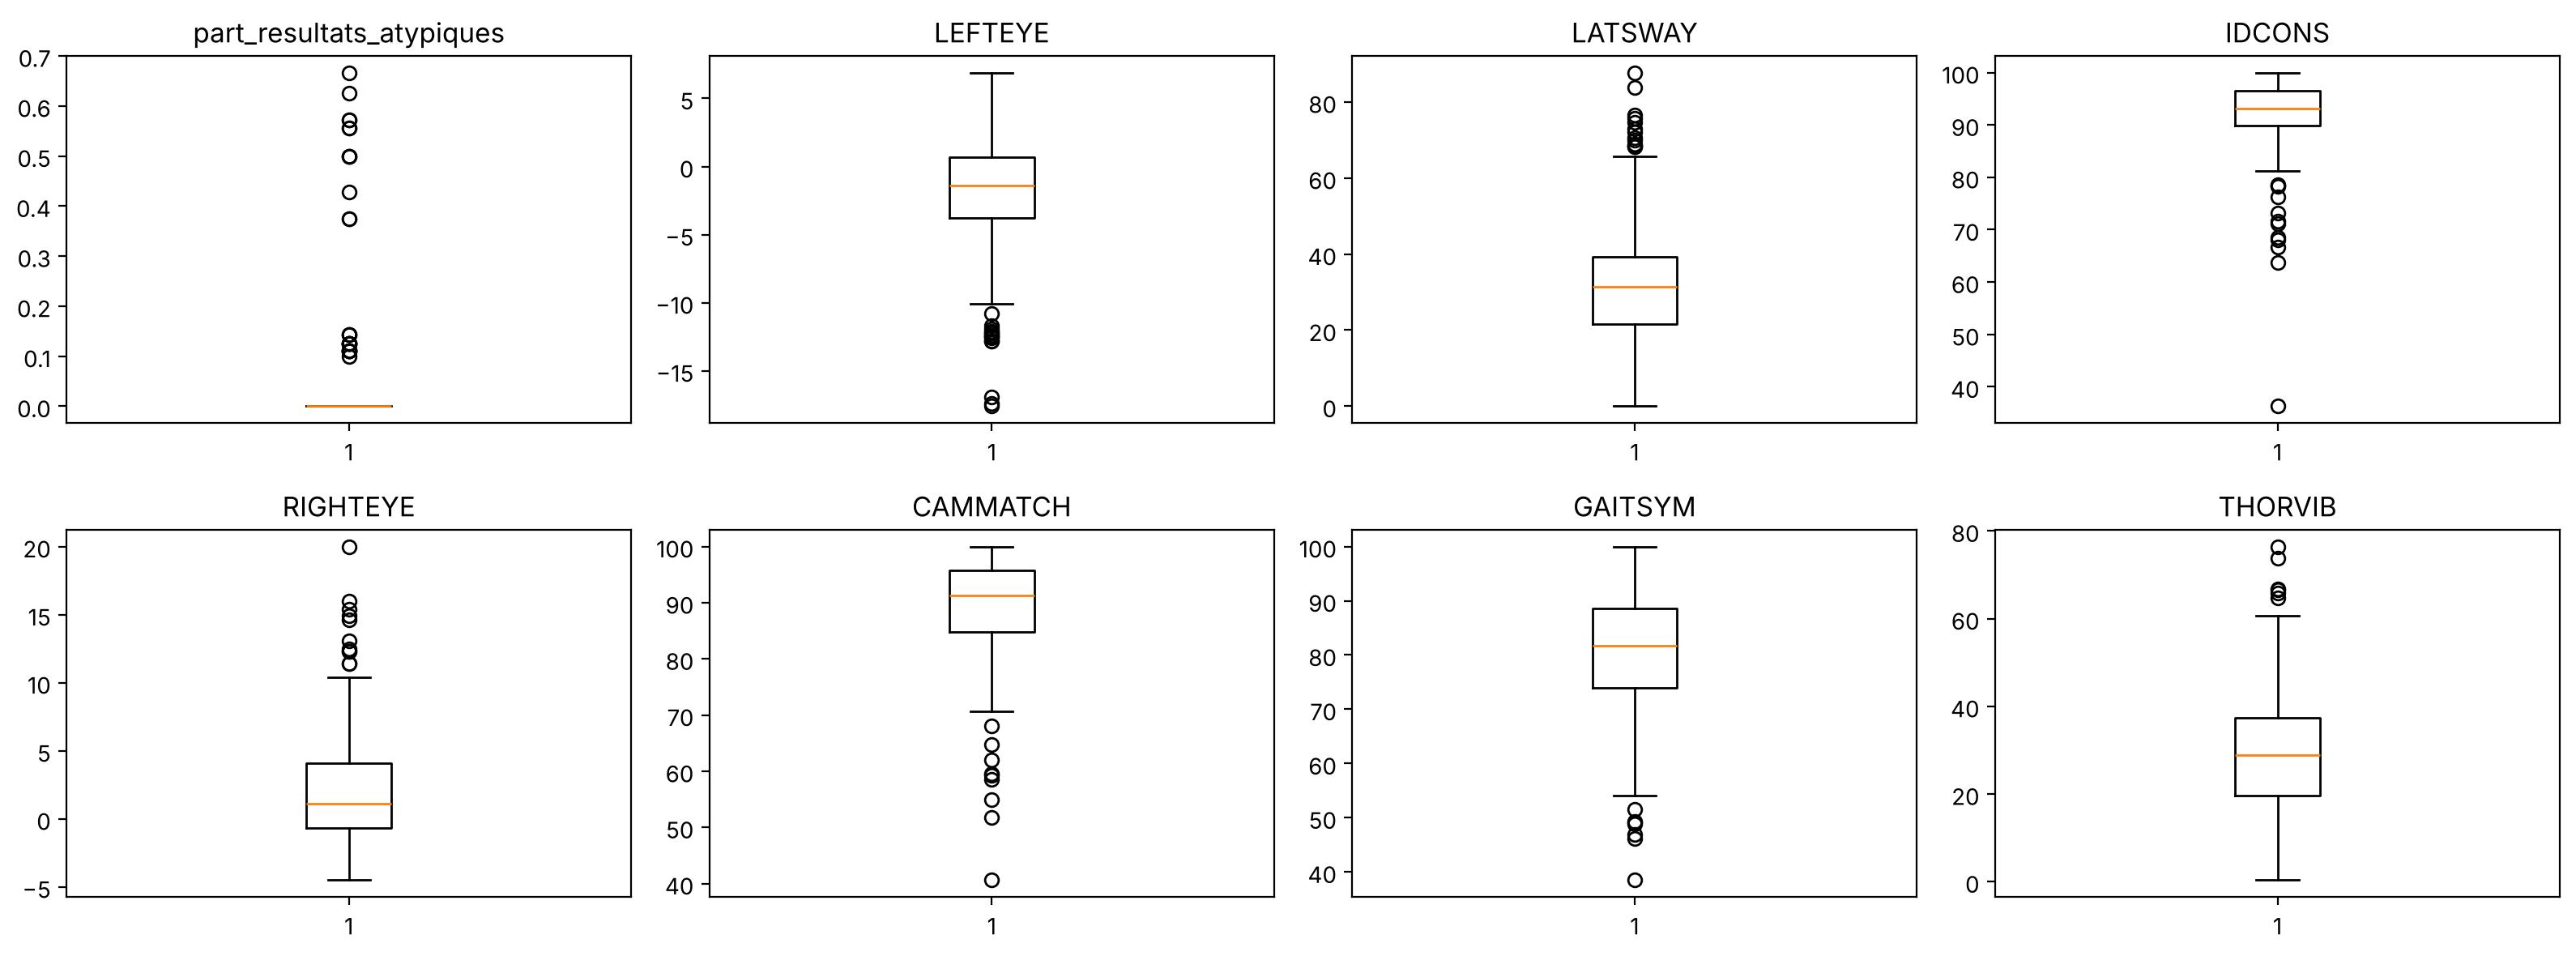

In [7]:
a_regarder = hors_bornes.sort_values(ascending=False).head(8).index
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, m in zip(axes.ravel(), a_regarder):
    ax.boxplot(tableau[m].dropna())
    ax.set_title(m)
plt.tight_layout()
plt.show()

Sur chaque boîte, les points isolés au-dessus ou en dessous sont les patients éloignés. Pour `IDCONS` et `CAMMATCH`, ils sont tous **en dessous** : quelques patients sont mal reconnus par les systèmes d'identification.

### Ces valeurs viennent-elles d'appareils défaillants ?

Avant d'aller plus loin, on vérifie une explication simple : peut-être que ces valeurs étranges sont dues à des erreurs de mesure. Le fichier contient une colonne `quality_code`, qui indique la qualité de chaque mesure.

In [8]:
observations["quality_code"].value_counts()

quality_code
acceptable    17734
Name: count, dtype: int64

Toutes les mesures ont une qualité « acceptable ». Cette piste ne donne rien : les valeurs étranges ne s'expliquent pas par un problème d'appareil.

## 5. Piste 2 : l'âge biologique

L'âge biologique estime l'âge du corps d'une personne. Normalement, il est proche de son âge réel. Comme c'est une mesure inhabituelle, on regarde si certains patients ont un âge biologique très différent de leur âge réel.

Pour chaque mesure de `BIOAGE`, on calcule l'âge réel du patient ce jour-là, à partir de sa date de naissance, puis l'**écart** entre les deux. Un écart positif veut dire que le patient paraît plus jeune que son âge.

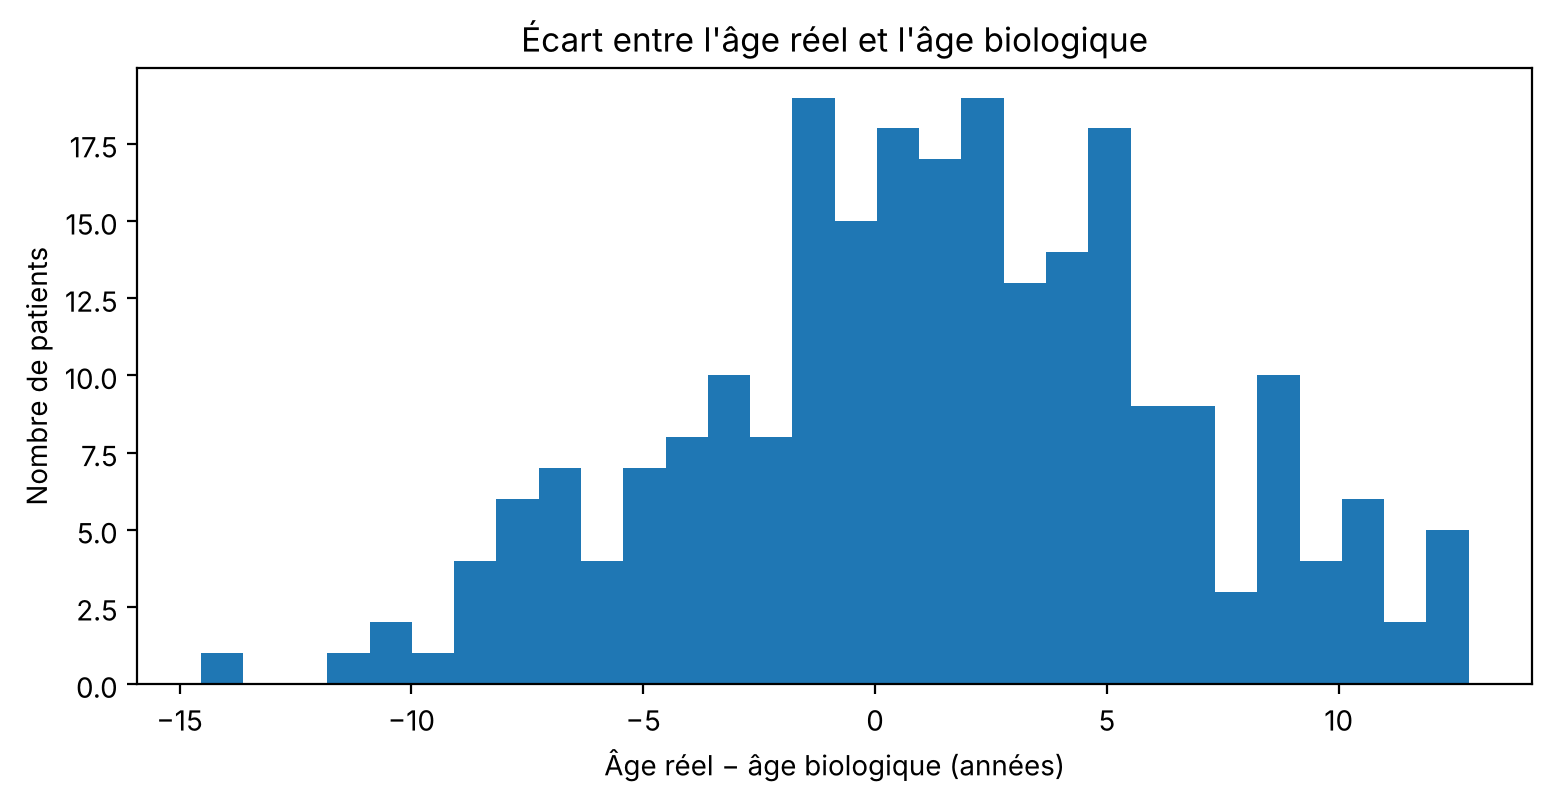

count    240.0
mean       1.4
std        5.2
min      -14.5
25%       -1.6
50%        1.4
75%        4.7
max       12.8
Name: ecart_age, dtype: float64

In [9]:
bio = observations[observations["observation_code"] == "BIOAGE"].merge(
    patients[["patient_number", "date_of_birth"]], on="patient_number")
bio["age_reel"] = (bio["observation_time"] - bio["date_of_birth"]).dt.days / 365.25
bio["ecart_age"] = bio["age_reel"] - bio["numeric_value"]

ecart = bio.groupby("patient_number")["ecart_age"].mean()

plt.figure(figsize=(9, 4))
plt.hist(ecart, bins=30)
plt.xlabel("Âge réel − âge biologique (années)")
plt.ylabel("Nombre de patients")
plt.title("Écart entre l'âge réel et l'âge biologique")
plt.show()

ecart.describe().round(1)

En moyenne, l'écart est d'environ 1 an : l'âge biologique suit bien l'âge réel. Mais certains patients paraissent jusqu'à 13 ans plus jeunes, et d'autres plus de 14 ans plus vieux.

On cherche d'abord des valeurs vraiment aberrantes avec l'IQR.

In [10]:
q1, q3 = ecart.quantile(0.25), ecart.quantile(0.75)
seuil = q3 + 1.5 * (q3 - q1)
print("Seuil :", round(seuil, 1), "ans")
print("Patients au-dessus :", (ecart > seuil).sum())

Seuil : 14.3 ans
Patients au-dessus : 0


Aucun patient ne dépasse le seuil. Pris un par un, personne n'est vraiment hors norme : la piste ne donne rien de cette façon.

On change donc d'angle. Plutôt que de chercher des valeurs extrêmes, on regarde **qui** sont les patients qui paraissent le plus jeunes : les 10 % d'écarts les plus grands.

In [11]:
seuil_10 = ecart.quantile(0.9)
jeunes = ecart[ecart >= seuil_10].round(1).to_frame("ecart_age").join(infos)
jeunes.sort_values("ecart_age", ascending=False)

,ecart_age,nom,occupation_text
patient_number,,,
PAT-31183,12.8,Adrienne Solva,executive director of ardena capital union
PAT-31016,12.6,Vera Perin,research assistant
PAT-31119,12.6,Celene Varro,chief executive of solvane energy group
PAT-31044,12.4,Tavian Serat,senior minister of the avelora federation
PAT-31221,12.2,Leora Kassen,head of government of kintara republic
PAT-31074,11.8,Oskar Nivren,executive chair of nivren maritime logistics
PAT-31178,11.8,Bela Elen,agricultural worker
PAT-31122,10.9,Yana Perin,small-business owner
PAT-31046,10.4,Marek Jorel,research assistant


Dans cette liste, il y a des métiers ordinaires, mais aussi des personnes très haut placées : la cheffe du gouvernement de Kintara, un ministre d'Avelora, un gouverneur, et les dirigeants de plusieurs grandes entreprises (Solvane Energy, Nivren Maritime Logistics, Ardena Capital Union, Belen Agro-Industries).

Pourquoi les dirigeants paraîtraient-ils plus jeunes que les autres ? On cherche ce qu'ils ont en commun du côté des soins qu'ils reçoivent.

## 6. Piste 3 : les actes médicaux

Le fichier `clinical_procedures` liste les actes médicaux réalisés. On regarde, pour chaque type d'acte, combien de fois il est fait, sur combien de patients différents, avec quelle autorisation, et s'il utilise un matériel.

In [12]:
resume = procedures.groupby("procedure_code").agg(
    description=("procedure_description", "first"),
    actes=("procedure_record_id", "count"),
    patients=("patient_number", "nunique"),
    autorisation=("authorization_class", lambda s: ", ".join(sorted(s.unique()))),
    avec_materiel=("material_reference", lambda s: s.notna().sum()),
)
resume

,description,actes,patients,autorisation,avec_materiel
procedure_code,,,,,
AGE-PNL,biological-age laboratory panel,39,36,confidential,0
AUT-REV,autonomic function review,43,41,confidential,0
CARD-IMG,advanced cardiac imaging,41,36,standard,0
MOB-PNL,mobility and balance panel,37,34,standard,0
MRP-42,targeted metabolic resilience administration,50,28,"research_restricted, restricted_specialist",50
OCC-PNL,occupational health assessment,49,47,standard,0
OCT-TRK,ocular tracking assessment,51,48,standard,0


Un acte ne ressemble pas aux autres : `MRP-42`, une « administration ciblée de résilience métabolique ».
- C'est le seul qui utilise un matériel, référencé pour les 50 actes.
- C'est le seul dont l'autorisation est restreinte.
- C'est le seul que certains patients reçoivent plusieurs fois : 50 actes pour 28 patients, alors que les autres actes sont presque toujours faits une seule fois par patient.

On regarde qui reçoit MRP-42 plusieurs fois.

In [13]:
mrp = procedures[procedures["procedure_code"] == "MRP-42"]
nombre_mrp = mrp["patient_number"].value_counts()
recurrents = nombre_mrp[nombre_mrp >= 2].to_frame("nombre de MRP-42").join(infos)
recurrents.join(ecart.round(1).rename("ecart_age"))

,nombre de MRP-42,nom,occupation_text,ecart_age
patient_number,,,,
PAT-31221,5,Leora Kassen,head of government of kintara republic,12.2
PAT-31044,4,Tavian Serat,senior minister of the avelora federation,12.4
PAT-31174,4,Mirek Talven,regional governor in the tembara commonwealth,10.2
PAT-31119,4,Celene Varro,chief executive of solvane energy group,12.6
PAT-31074,4,Oskar Nivren,executive chair of nivren maritime logistics,11.8
PAT-31183,3,Adrienne Solva,executive director of ardena capital union,12.8
PAT-31142,3,Rayan Belen,chair of belen agro-industries,9.8
PAT-31099,3,Elira Vaun,retired political intermediary and former coun...,8.8


Huit patients reçoivent MRP-42 de 3 à 5 fois, et ce sont tous des personnes haut placées : la cheffe du gouvernement de Kintara, le ministre, le gouverneur, l'ancienne présidente du conseil d'Avelora et quatre dirigeants d'entreprise. Et tous paraissent entre 9 et 13 ans plus jeunes que leur âge.

### Est-ce un hasard ?

Pour vérifier que ce lien n'est pas dû au hasard, on calcule des règles d'association. On décrit chaque patient par trois informations (oui ou non) :
- il a reçu MRP-42 plusieurs fois ;
- il fait partie des 10 % qui paraissent le plus jeunes ;
- il occupe un poste de direction politique ou économique.

Pour une règle « si A, alors B », la **confiance** dit combien de patients qui ont A ont aussi B. Le **lift** dit combien de fois c'est plus fréquent que si A et B n'avaient aucun rapport : un lift de 1 veut dire « pas de lien ».

In [14]:
mots_dirigeant = ["head of government", "minister", "governor", "chief executive",
                  "executive chair", "executive director", "chair of", "council president"]
occupation = patients.set_index("patient_number")["occupation_text"]

profil = pd.DataFrame(index=patients["patient_number"])
profil["MRP-42 répété"] = profil.index.isin(recurrents.index)
profil["paraît plus jeune"] = profil.index.isin(jeunes.index)
profil["dirigeant"] = occupation.str.contains("|".join(mots_dirigeant)).reindex(profil.index)

def regle(a, b):
    A, B = profil[a], profil[b]
    confiance = (A & B).sum() / A.sum()
    return {"règle": f"si {a}, alors {b}",
            "patients concernés": int((A & B).sum()),
            "confiance": round(confiance, 2),
            "lift": round(confiance / B.mean(), 1)}

pd.DataFrame([
    regle("MRP-42 répété", "dirigeant"),
    regle("dirigeant", "MRP-42 répété"),
    regle("MRP-42 répété", "paraît plus jeune"),
])

,règle,patients concernés,confiance,lift
0,"si MRP-42 répété, alors dirigeant",8,1.0,24.0
1,"si dirigeant, alors MRP-42 répété",8,0.8,24.0
2,"si MRP-42 répété, alors paraît plus jeune",8,1.0,10.0


Les trois règles vont dans le même sens :
- tous les patients qui reçoivent MRP-42 plusieurs fois sont des dirigeants, 24 fois plus souvent que par hasard ;
- sur les 10 dirigeants de la base, 8 reçoivent ce traitement ;
- tous les patients traités paraissent plus jeunes, 10 fois plus souvent que par hasard.

On compare enfin l'écart d'âge des patients traités à celui des autres.

In [15]:
groupe = np.where(ecart.index.isin(recurrents.index), "MRP-42 répété", "autres patients")
ecart.groupby(groupe).describe().round(1)

,count,mean,std,min,25%,50%,75%,max
MRP-42 répété,8.0,11.3,1.5,8.8,10.1,12.0,12.5,12.8
autres patients,232.0,1.0,5.0,-14.5,-2.0,1.2,4.5,12.6


Les 8 patients traités paraissent en moyenne 11 ans plus jeunes que leur âge, contre 1 an pour les autres.

Ces 8 personnes ne sont que 8, mais la règle ne souffre d'aucune exception. On garde cette piste : il faudra savoir de quoi est fait MRP-42 (sa référence de matériel) et si ces personnes apparaissent ailleurs, par exemple dans les nominations publiques.

## 7. Piste 4 : des patients qui ne ressemblent à personne

Dans la piste 1, plusieurs mesures étranges avaient des valeurs éloignées. On se demande maintenant si ce sont **les mêmes patients** qui ont des valeurs étranges sur plusieurs mesures à la fois.

On garde les mesures qui avaient le plus de valeurs éloignées. On y ajoute une mesure qu'on construit nous-mêmes : la différence entre le pouls pris au cœur (`APICAL`) et le pouls pris au poignet (`PPULSE`). Chez une personne ordinaire, les deux comptent les mêmes battements et doivent donc être très proches.

In [16]:
tableau["ecart_coeur_poignet"] = tableau["APICAL"] - tableau["PPULSE"]

mesures_retenues = ["LEFTEYE", "RIGHTEYE", "LATSWAY", "GAITSYM", "IDCONS", "CAMMATCH",
                    "THORVIB", "THORPEAK", "ecart_coeur_poignet", "part_resultats_atypiques"]

# Quelques patients n'ont pas toutes les mesures : on complète par la valeur médiane
X = tableau[mesures_retenues].fillna(tableau[mesures_retenues].median())

# Les mesures n'ont pas la même unité (degrés, battements, scores…) :
# on les remet toutes à la même échelle pour qu'aucune ne compte plus qu'une autre
X_std = StandardScaler().fit_transform(X)

### Premier essai : le LOF

Le LOF compare chaque patient à ses voisins les plus proches : un patient entouré de peu de voisins est jugé atypique.

In [17]:
lof = LocalOutlierFactor(n_neighbors=20)
lof.fit(X_std)
score_lof = pd.Series(-lof.negative_outlier_factor_, index=X.index, name="score_lof")
score_lof.sort_values(ascending=False).head(10).round(2).to_frame().join(infos)

,score_lof,nom,occupation_text
patient_number,,,
PAT-31039,2.25,Liora Uren,senior field analyst
PAT-31081,2.17,Orin Kerin,compliance counsel
PAT-31163,2.08,Gita Corda,research assistant
PAT-31233,2.02,Mara Ven,research professional
PAT-31139,1.98,Kira Havel,retired professional
PAT-31031,1.93,Daria Aster,teacher
PAT-31152,1.86,Celia Wessen,small-business owner
PAT-31007,1.82,Marek Kerin,wildlife programme officer
PAT-31012,1.78,Amara Sen,research professional


Les patients que le LOF met en tête sont très variés (enseignants, retraités, analystes…). On y croise quelques noms qui reviendront plus loin (Mara Ven, Celia Wessen, Amara Sen), mais mélangés à d'autres profils sans point commun. Cette piste ne donne pas grand-chose.

Une explication possible : si plusieurs patients atypiques se ressemblent **entre eux**, ils sont voisins les uns des autres. Chacun a donc des voisins proches, et le LOF ne les trouve pas isolés.

### Deuxième essai : l'Isolation Forest

L'Isolation Forest cherche plutôt les patients **faciles à séparer de la masse**, même s'ils forment un petit groupe. On essaie avec cette méthode.

In [18]:
foret = IsolationForest(random_state=0)
foret.fit(X_std)
profils = pd.Series(-foret.score_samples(X_std), index=X.index, name="score_isolation").round(3)
profils = profils.to_frame().join(infos).sort_values("score_isolation", ascending=False)
profils.head(12)

,score_isolation,nom,occupation_text
patient_number,,,
PAT-31233,0.681,Mara Ven,research professional
PAT-31162,0.645,Eli Varen,corporate adviser
PAT-31065,0.640,Corin Hallen,clinical specialist
PAT-31037,0.634,Sel Aran,research professional
PAT-31086,0.618,Niko Veran,corporate adviser
PAT-31186,0.613,Soren Kader,corporate adviser
PAT-31152,0.595,Celia Wessen,small-business owner
PAT-31012,0.581,Amara Sen,research professional
PAT-31215,0.578,Ilan Roe,research professional


Cette fois, les premiers patients ont des profils semblables : des conseillers, des chercheurs et des spécialistes cliniques. On garde les 10 premiers, et on regarde en quoi ils diffèrent des autres patients.

In [19]:
atypiques = profils.index[:10]
X_std_df = pd.DataFrame(X_std, index=X.index, columns=X.columns)
difference = X_std_df.loc[atypiques].mean() - X_std_df.drop(atypiques).mean()
difference.sort_values(key=abs, ascending=False).round(1).to_frame("différence avec les autres")

,différence avec les autres
observation_code,
part_resultats_atypiques,3.5
ecart_coeur_poignet,2.4
IDCONS,-2.2
CAMMATCH,-2.1
THORVIB,1.8
THORPEAK,1.7
LATSWAY,1.5
RIGHTEYE,0.9
LEFTEYE,-0.6


Une différence de 1 veut dire que le groupe s'écarte des autres patients d'environ une « distance habituelle » entre patients ; une différence de 3 est donc très grande. Par rapport aux autres, ces 10 patients ont :
- beaucoup plus de résultats atypiques aux tests des yeux et de l'équilibre ;
- un pouls au cœur très différent du pouls au poignet ;
- une identification par caméra beaucoup moins fiable ;
- plus de vibrations et de pics dans la poitrine ;
- plus d'oscillation quand ils marchent.

Pour visualiser tout ça, on résume les 10 mesures en deux axes avec une ACP, puis on place les patients : les 10 patients retenus sont en rouge.

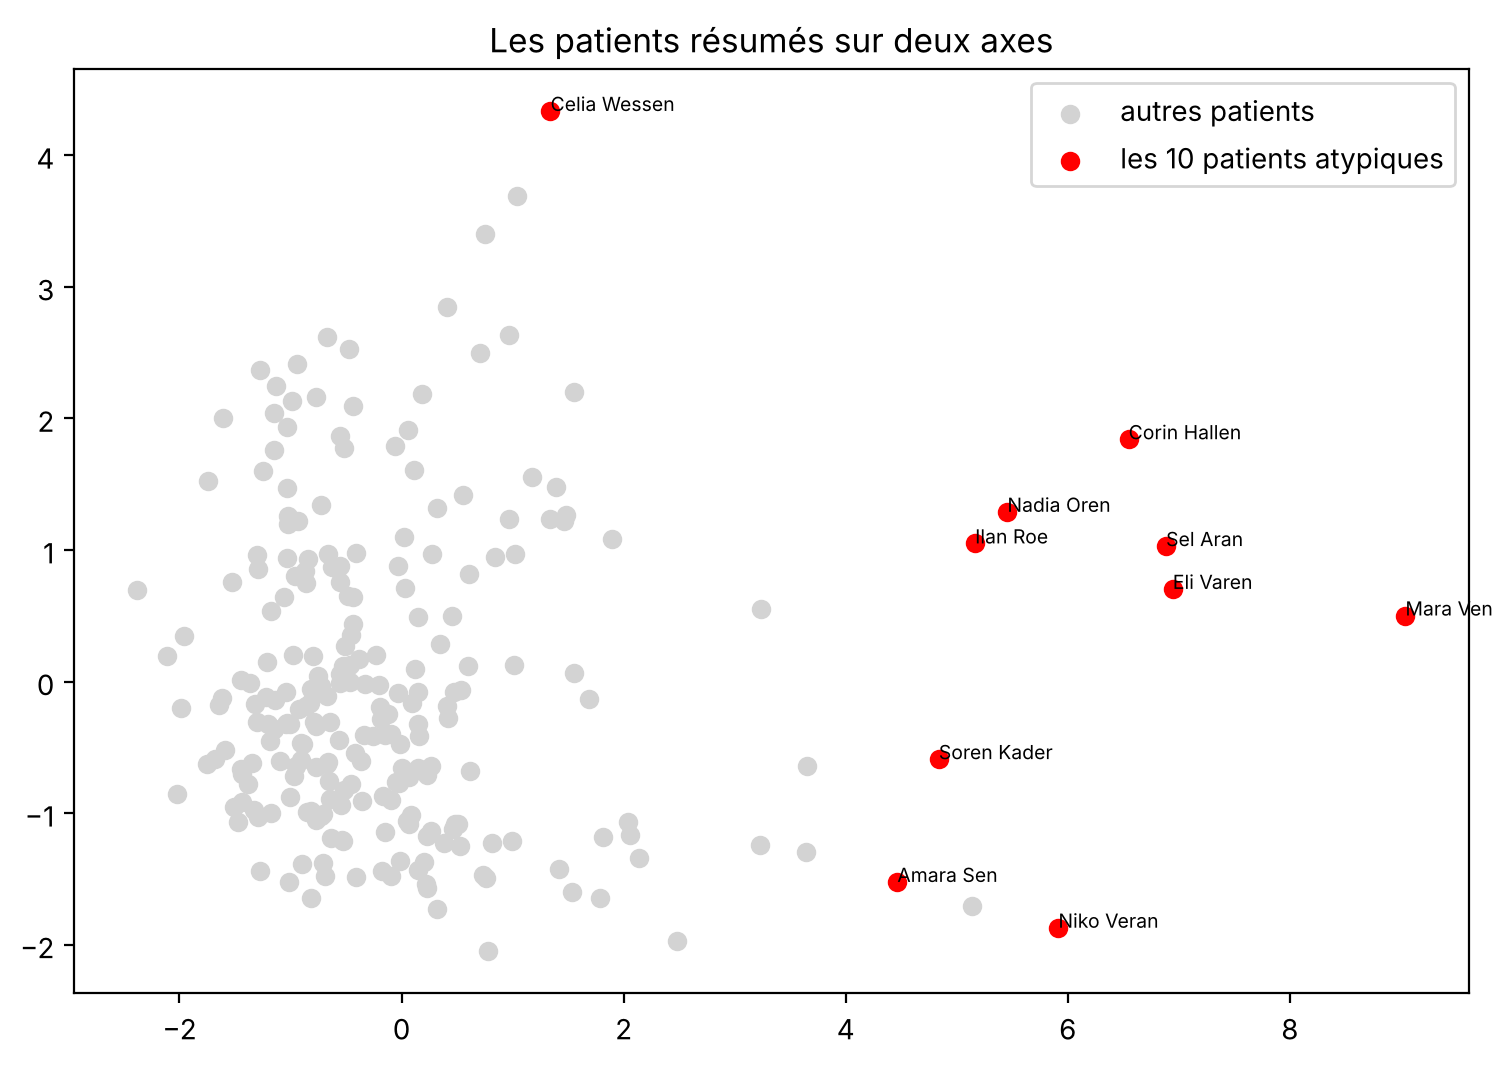

In [20]:
coords = PCA(n_components=2).fit_transform(X_std)
rouge = X.index.isin(atypiques)
plt.figure(figsize=(9, 6))
plt.scatter(coords[~rouge, 0], coords[~rouge, 1], c="lightgray", label="autres patients")
plt.scatter(coords[rouge, 0], coords[rouge, 1], c="red", label="les 10 patients atypiques")
for i in np.where(rouge)[0]:
    plt.annotate(infos.loc[X.index[i], "nom"], coords[i], fontsize=7)
plt.legend()
plt.title("Les patients résumés sur deux axes")
plt.show()

Les patients en rouge sont regroupés à l'écart de tous les autres : ils forment bien un groupe à part, ce qui explique aussi pourquoi le LOF ne les trouvait pas.

On remarque que ce ne sont pas les mêmes personnes que les 8 dirigeants de la piste 3 : il y a donc deux groupes différents. Certains noms ressemblent aussi à des noms vus dans d'autres domaines (Soren Kader, Corin Hallen…) : on le vérifiera lors des croisements.

## 8. Piste 5 : le cœur

Dans la piste 4, le pouls pris au cœur et celui pris au poignet ne correspondaient pas chez certains patients. On a aussi des enregistrements cardiaques complets, avec deux capteurs (canal `a` et canal `b`). Si les deux capteurs écoutent le même cœur, ils doivent battre au même rythme. On vérifie.

Pour trouver le rythme d'un signal, on cherche au bout de combien de temps il se répète. On compare le signal avec lui-même décalé dans le temps (c'est l'autocorrélation) : le décalage pour lequel il se ressemble le plus donne la durée d'un battement, et donc le nombre de battements par minute.

In [21]:
def rythme(signal, frequence):
    x = signal - signal.mean()
    ressemblance = np.correlate(x, x, "full")[len(x) - 1:] / (x @ x)
    debut, fin = int(frequence * 0.25), int(frequence * 2)   # on cherche entre 30 et 240 battements par minute
    k = np.argmax(ressemblance[debut:fin])
    battements_par_minute = round(60 * frequence / (debut + k))
    regularite = round(ressemblance[debut + k], 2)            # proche de 1 = signal très régulier
    return battements_par_minute, regularite

resultats = []
for rid, g in signaux.sort_values("time_ms").groupby("recording_id"):
    frequence = 1000 / g["time_ms"].diff().median()
    rythme_a, regularite_a = rythme(g["channel_a_normalized"].values, frequence)
    rythme_b, regularite_b = rythme(g["channel_b_normalized"].values, frequence)
    resultats.append({"recording_id": rid, "rythme_a": rythme_a, "rythme_b": rythme_b,
                      "regularite_a": regularite_a, "regularite_b": regularite_b})

coeur = (pd.DataFrame(resultats)
         .merge(enregistrements[["recording_id", "patient_number"]], on="recording_id")
         .join(infos, on="patient_number"))
coeur["ecart_rythme"] = (coeur["rythme_a"] - coeur["rythme_b"]).abs()
coeur.sort_values("ecart_rythme", ascending=False).head(12)

,recording_id,rythme_a,rythme_b,regularite_a,regularite_b,patient_number,nom,occupation_text,ecart_rythme
16,CRD-410017,35,221,0.67,0.52,PAT-31130,Lena Soren,administrative employee,186
11,CRD-410012,182,39,0.11,0.15,PAT-31057,Kira Elen,accreditation officer,143
40,CRD-410041,35,90,0.53,0.54,PAT-31155,Galen Soren,retired professional,55
4,CRD-410005,67,100,0.79,0.80,PAT-31065,Corin Hallen,clinical specialist,33
37,CRD-410038,66,99,0.79,0.81,PAT-31065,Corin Hallen,clinical specialist,33
21,CRD-410022,71,97,0.78,0.78,PAT-31037,Sel Aran,research professional,26
24,CRD-410025,80,99,0.78,0.76,PAT-31040,Jonah Valen,research professional,19
27,CRD-410028,72,54,0.65,0.52,PAT-31211,Nora Iven,administrative employee,18
30,CRD-410031,70,87,0.75,0.71,PAT-31162,Eli Varen,corporate adviser,17
18,CRD-410019,71,88,0.78,0.80,PAT-31162,Eli Varen,corporate adviser,17


Plusieurs enregistrements ont des rythmes différents sur les deux canaux. Mais un signal brouillé peut aussi donner un faux rythme : les deux premiers, par exemple, ont une régularité faible.

On ne garde donc que les enregistrements où **les deux canaux sont réguliers** (régularité supérieure à 0,7) et où **leurs rythmes diffèrent nettement** (plus de 10 battements par minute).

In [22]:
deux_rythmes = coeur[(coeur["regularite_a"] > 0.7) & (coeur["regularite_b"] > 0.7)
                     & (coeur["ecart_rythme"] > 10)]
deux_rythmes

,recording_id,rythme_a,rythme_b,regularite_a,regularite_b,patient_number,nom,occupation_text,ecart_rythme
4,CRD-410005,67,100,0.79,0.80,PAT-31065,Corin Hallen,clinical specialist,33
13,CRD-410014,74,90,0.82,0.81,PAT-31233,Mara Ven,research professional,16
18,CRD-410019,71,88,0.78,0.80,PAT-31162,Eli Varen,corporate adviser,17
21,CRD-410022,71,97,0.78,0.78,PAT-31037,Sel Aran,research professional,26
24,CRD-410025,80,99,0.78,0.76,PAT-31040,Jonah Valen,research professional,19
30,CRD-410031,70,87,0.75,0.71,PAT-31162,Eli Varen,corporate adviser,17
37,CRD-410038,66,99,0.79,0.81,PAT-31065,Corin Hallen,clinical specialist,33


On compare un enregistrement ordinaire et un enregistrement à deux rythmes.

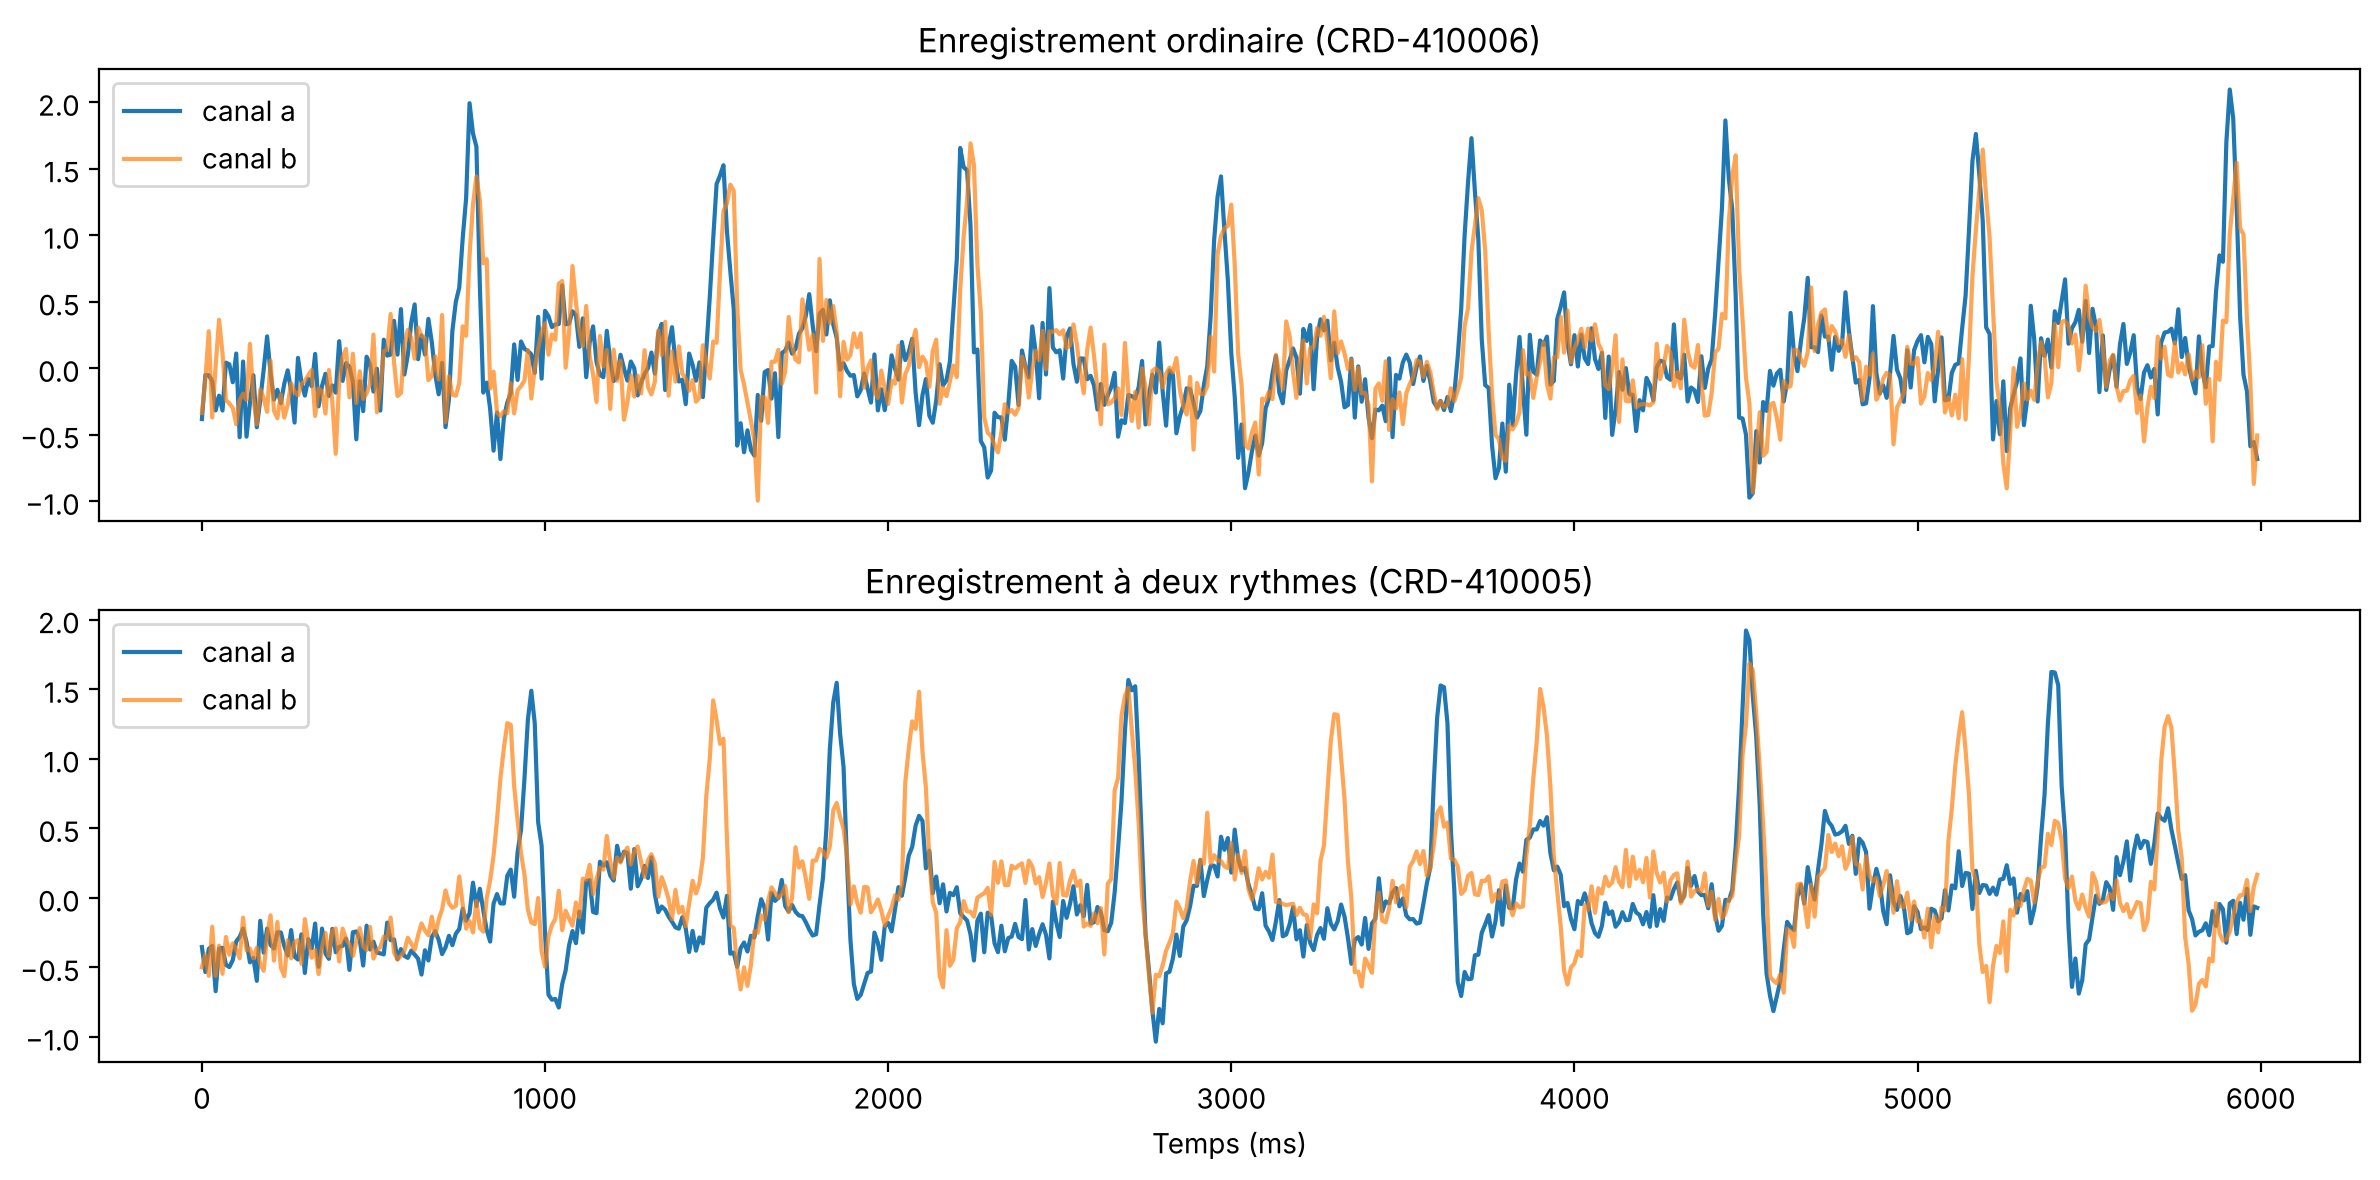

In [23]:
ordinaire = coeur[(coeur["regularite_a"] > 0.7) & (coeur["ecart_rythme"] == 0)]["recording_id"].iloc[0]
double = deux_rythmes["recording_id"].iloc[0]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, rid, titre in [(axes[0], ordinaire, "Enregistrement ordinaire"),
                       (axes[1], double, "Enregistrement à deux rythmes")]:
    g = signaux[signaux["recording_id"] == rid].sort_values("time_ms").head(600)
    ax.plot(g["time_ms"], g["channel_a_normalized"], label="canal a")
    ax.plot(g["time_ms"], g["channel_b_normalized"], label="canal b", alpha=0.7)
    ax.set_title(f"{titre} ({rid})")
    ax.legend()
axes[1].set_xlabel("Temps (ms)")
plt.tight_layout()
plt.show()

En haut, les deux canaux montent et descendent ensemble. En bas, ils se décalent peu à peu : chacun suit son propre rythme, comme si chaque capteur écoutait un cœur différent.

Il reste 7 enregistrements, qui appartiennent à 5 patients : Corin Hallen, Mara Ven, Eli Varen, Sel Aran et Jonah Valen. Les quatre premiers font partie des 10 patients atypiques de la piste 4, et Jonah Valen arrivait juste après, en 11e position. Deux méthodes différentes, sur deux fichiers différents, désignent donc presque les mêmes personnes.

## 9. Bilan

| Piste | Ce qu'on a fait | Résultat |
|---|---|---|
| Valeurs qui sortent du lot | IQR sur chaque mesure | Les mesures classiques sont ordinaires ; les mesures étranges (yeux, identité, poitrine, démarche) ont beaucoup de valeurs éloignées |
| Erreurs d'appareil | Qualité des mesures | Rien : toutes les mesures sont de qualité acceptable |
| Âge biologique | Écart avec l'âge réel, IQR | Aucune valeur aberrante prise seule, mais des dirigeants parmi les patients qui paraissent le plus jeunes |
| Actes médicaux | Description des actes, règles d'association | 8 dirigeants reçoivent MRP-42 de façon répétée et paraissent 11 ans plus jeunes |
| Profils atypiques | LOF, puis Isolation Forest et ACP | Le LOF ne donne rien ; l'Isolation Forest isole un groupe de 10 patients au profil très inhabituel |
| Le cœur | Autocorrélation des signaux | 5 patients, tous dans ce groupe ou juste à côté, ont deux rythmes cardiaques distincts |

On retient donc deux groupes :
1. **8 dirigeants** qui reçoivent un traitement restreint, MRP-42, et paraissent beaucoup plus jeunes que leur âge ;
2. **10 patients** dont le corps semble différent : yeux, démarche, poitrine, deux cœurs, et des caméras qui ont du mal à les reconnaître.

Chaque signe pris seul pourrait avoir une explication ordinaire ; c'est leur combinaison chez les mêmes personnes qui est remarquable. Et un lien entre MRP-42 et la jeunesse ne prouve pas à lui seul que le traitement en est la cause.

**Questions pour la suite :**
- Ces 8 dirigeants occupent-ils leurs fonctions depuis anormalement longtemps ? (public records)
- De quoi est fait le matériel de MRP-42 ? (logistique)
- Qui sont vraiment les 10 patients atypiques ? Leurs noms ressemblent-ils à ceux d'autres personnes ? (croisements)